# Simulate and filter

This notebook walks through the method so far, from the data-generating process to posterior inference, on one baseline dataset ($n = 50$ agents, $T = 100$ steps). Everything is computed by the library in `src/`; the notebook only calls it, builds small tables and plots. Figures are also saved under `results/notebook02/`.

## 0. Setup

Load the baseline model config and the inference config, and simulate one dataset with the baseline seed.

In [1]:
import os

# One BLAS thread per process (set before NumPy loads): on these small matrices multithreaded BLAS is
# much slower, and the heavy loops below run in parallel processes instead.
for blas_thread_variable in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "OMP_NUM_THREADS"):
    os.environ[blas_thread_variable] = "1"

import sys
import time
from concurrent.futures import ProcessPoolExecutor
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from IPython.display import Image, Markdown, display

REPO_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from checks.common import profile_width, self_weight_profile, with_model_params
from checks.plotting import (
    ESTIMATE_STYLE, EXACT_STYLE, POINTS_STYLE, ProfileCurve, mark_true_value, plot_self_weight_profiles,
    save_figure, set_log_ticks, style_axes,
)
from src import inference, kalman, simulate
from src.config import load_config
from src.neighbour_inputs import INPUT_MODES
from src.particle_filter import draw_per_agent_noise, per_agent_pf_loglik, per_agent_pf_loglik_given_noise

FIGURE_DIR = REPO_ROOT / "results" / "notebook02"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
section_runtimes = {}


def show_figure(fig, file_name):
    """Save the figure under results/notebook02/ (shared save_figure) and display the PNG."""
    path = save_figure(fig, FIGURE_DIR / file_name)
    display(Image(filename=str(path)))


def show_table(headers, rows):
    """Display a small Markdown table."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


section_start = time.perf_counter()
config = load_config(REPO_ROOT / "configs" / "degroot_base.yaml")
inference_config = inference.load_inference_config(REPO_ROOT / "configs" / "inference_base.yaml")
for name, section in [("network", config.network), ("simulation", config.simulation), ("model", config.model),
                      ("priors", inference_config.priors), ("mcmc", inference_config.mcmc),
                      ("pmmh", inference_config.pmmh)]:
    print(f"{name:<11} {section}")

dataset = simulate.simulate(config)
opinions, expressions, labels, W = dataset["x"], dataset["s"], dataset["y"], dataset["W"]
n_steps, n_agents = labels.shape
true_params = config.model
simulation_settings = config.simulation
true_values = {"self_weight": true_params.self_weight, "process_noise_sd": true_params.process_noise_sd,
               "expression_noise_sd": true_params.expression_noise_sd}
SHOWN_AGENTS = [3, 21, 40]
time_steps = np.arange(n_steps)
print(f"\nSimulated x, s, Y of shape {labels.shape} (T, n); seed {config.seed}")
section_runtimes["0. Setup"] = time.perf_counter() - section_start

network     NetworkConfig(type='watts_strogatz', n_agents=50, k=4, p=0.1)
simulation  SimulationConfig(T=100, x0_mean=0.5, x0_sd=0.2)
model       ModelParams(dynamics='degroot', self_weight=0.3, process_noise_sd=0.05, expression_noise_sd=0.05, measurement_noise_sd=0.1, observation='continuous')
priors      Priors(self_weight=UniformPrior(low=0.0, high=1.0), process_noise_sd=LognormalPrior(median=0.1, log_sd=1.0), expression_noise_sd=LognormalPrior(median=0.1, log_sd=1.0))
mcmc        MCMCConfig(n_iterations=10000, burn_in=2000, adapt_every=100, initial_step_sd=0.02)
pmmh        PMMHConfig(n_particles=100, rho=0.99, input_mode='filtered_var')

Simulated x, s, Y of shape (100, 50) (T, n); seed 42


## 1. The data-generating process

**Question:** what do the data look like, and how much of each label is signal?

Each agent's hidden opinion follows DeGroot with noise, driven by the neighbours' *expressions*; researchers only see noisy labels of those expressions:

$$
x_{i,t} = \lambda\, x_{i,t-1} + (1-\lambda)\sum_j W_{ij}\, s_{j,t-1} + \varepsilon_{i,t}, \qquad s_{i,t} = x_{i,t} + \xi_{i,t}, \qquad Y_{i,t} = s_{i,t} + e_{i,t},
$$

with $\varepsilon \sim \mathcal N(0, \sigma_p^2)$, $\xi \sim \mathcal N(0, \sigma_e^2)$, $e \sim \mathcal N(0, \sigma_m^2)$. Look for how far the crosses ($Y$) scatter around the line ($x$) compared with how much $x$ itself moves.

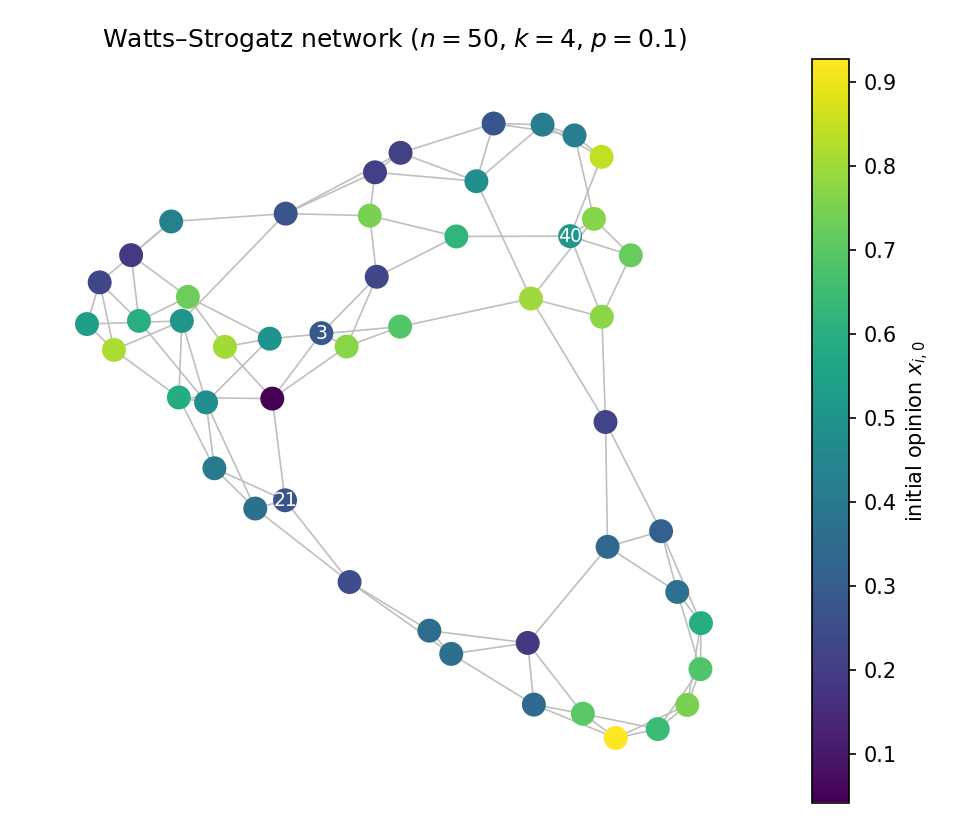

In [2]:
section_start = time.perf_counter()
graph = dataset["graph"]
layout = nx.spring_layout(graph, seed=1)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
nx.draw_networkx_edges(graph, layout, ax=ax, edge_color="0.75", width=0.8)
nodes = nx.draw_networkx_nodes(graph, layout, ax=ax, node_color=opinions[0], cmap="viridis", node_size=110)
nx.draw_networkx_labels(graph, layout, labels={agent: str(agent) for agent in SHOWN_AGENTS}, ax=ax, font_size=9,
                        font_color="white")
fig.colorbar(nodes, ax=ax, label=r"initial opinion $x_{i,0}$")
ax.set_title(rf"Watts–Strogatz network ($n = {n_agents}$, $k = {config.network.k}$, $p = {config.network.p}$)")
ax.axis("off")
show_figure(fig, "network.png")

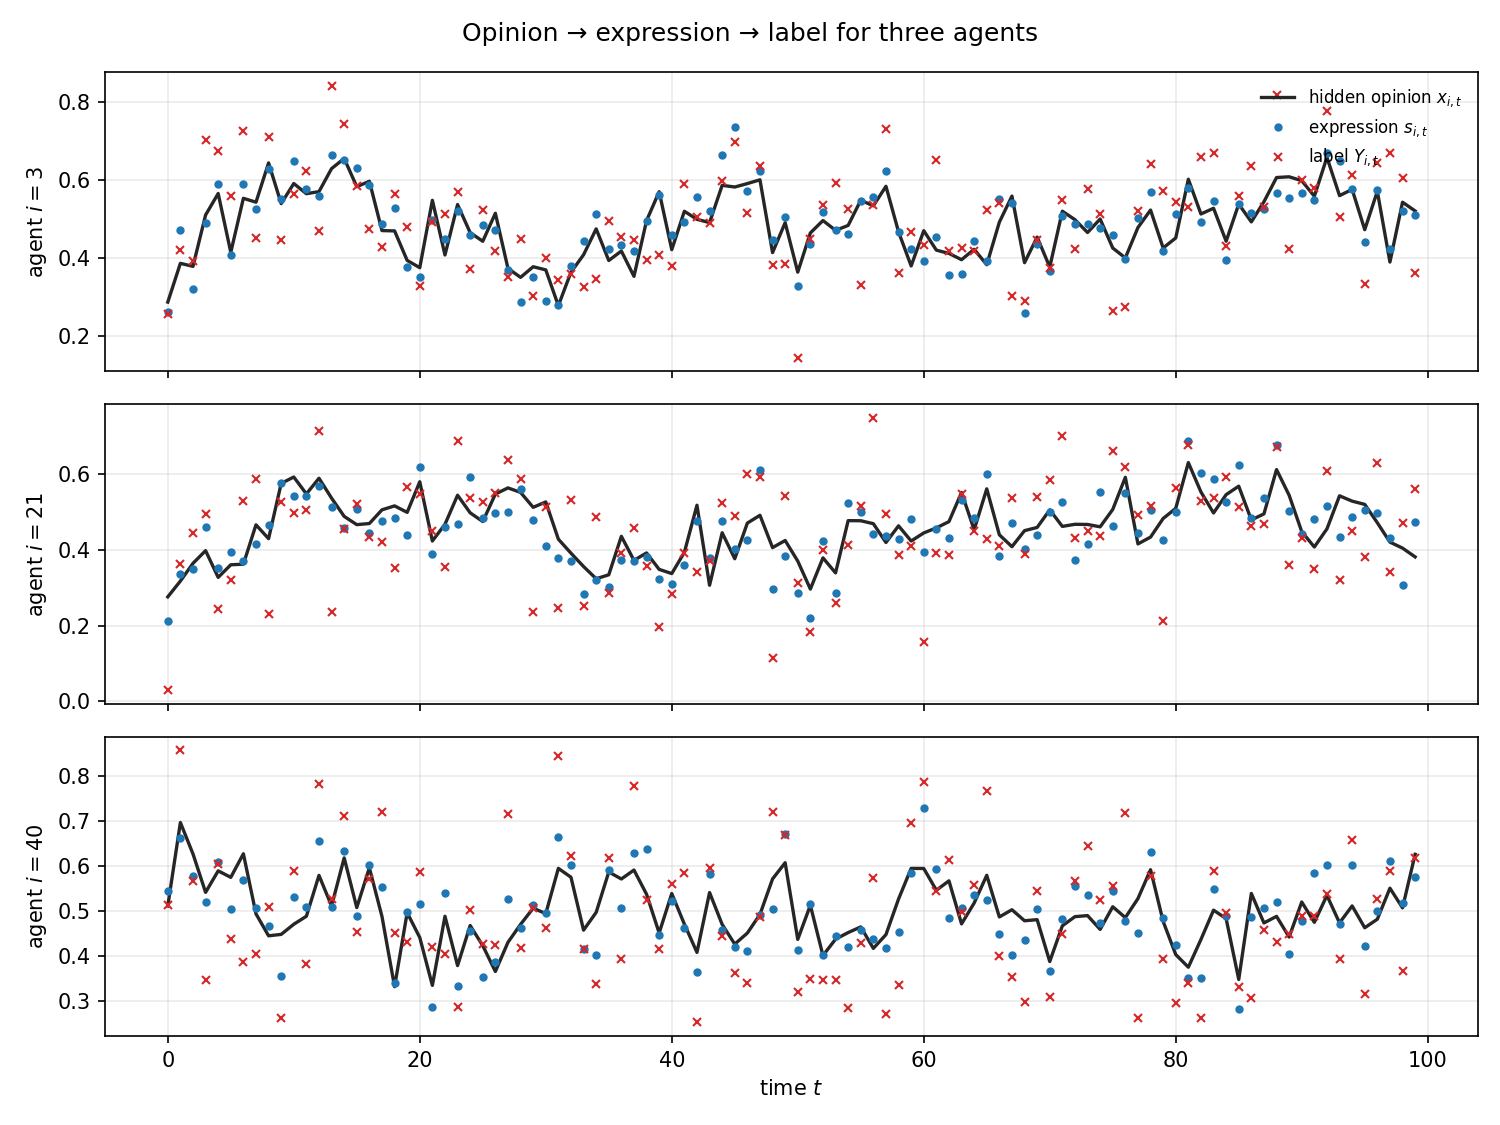

| quantity | value | config |
|---|---|---|
| std of hidden opinions $x$ (all agents and times) | 0.0801 |  |
| std of $s - x$ (expression noise) | 0.0497 | $\sigma_e = 0.05$ |
| std of $Y - s$ (measurement noise) | 0.1002 | $\sigma_m = 0.1$ |
| signal-to-noise $\mathrm{std}(x) / \sqrt{\sigma_e^2 + \sigma_m^2}$ | 0.72 |  |

In [3]:
fig, axes = plt.subplots(len(SHOWN_AGENTS), 1, figsize=(10, 7.5), sharex=True)
for ax, agent in zip(axes, SHOWN_AGENTS):
    ax.plot(time_steps, opinions[:, agent], color="0.15", linewidth=1.6, label=r"hidden opinion $x_{i,t}$")
    ax.plot(time_steps, expressions[:, agent], color="C0", linestyle="none", marker="o", markersize=3,
            label=r"expression $s_{i,t}$")
    ax.plot(time_steps, labels[:, agent], color="C3", linestyle="none", marker="x", markersize=4,
            label=r"label $Y_{i,t}$")
    style_axes(ax, r"time $t$" if agent == SHOWN_AGENTS[-1] else "", rf"agent $i = {agent}$",
               legend=agent == SHOWN_AGENTS[0], legend_location="upper right", legend_fontsize=8)
fig.suptitle("Opinion → expression → label for three agents")
show_figure(fig, "opinion_expression_label.png")

expression_noise, measurement_noise = true_params.expression_noise_sd, true_params.measurement_noise_sd
opinion_spread = opinions.std()
signal_to_noise = opinion_spread / np.sqrt(expression_noise**2 + measurement_noise**2)
show_table(["quantity", "value", "config"], [
    [r"std of hidden opinions $x$ (all agents and times)", f"{opinion_spread:.4f}", ""],
    [r"std of $s - x$ (expression noise)", f"{(expressions - opinions).std():.4f}", rf"$\sigma_e = {expression_noise}$"],
    [r"std of $Y - s$ (measurement noise)", f"{(labels - expressions).std():.4f}", rf"$\sigma_m = {measurement_noise}$"],
    [r"signal-to-noise $\mathrm{std}(x) / \sqrt{\sigma_e^2 + \sigma_m^2}$", f"{signal_to_noise:.2f}", ""],
])
section_runtimes["1. Data-generating process"] = time.perf_counter() - section_start

**Takeaway.** Hidden opinions vary with sd $0.080$ across agents and time, while a label sits about $\sqrt{\sigma_e^2 + \sigma_m^2} = 0.112$ from the opinion (measured: $0.050$ for $s - x$, $0.100$ for $Y - s$). The signal-to-noise ratio is $0.72$: a single label carries more noise than signal, so opinions must be inferred by pooling over time and neighbours.

## 2. Recovering hidden opinions

**Question:** with the parameters known, how well can the filters reconstruct $x_{i,t}$ from the labels up to $t$?

- *Joint Kalman*: exact for this linear-Gaussian model; tracks all agents and their expressions together.
- *Per-agent Kalman*: one scalar filter per agent; neighbours' expressions enter as inputs, either the raw labels (`observed`) or their filtered estimates plus uncertainty (`filtered_var`).
- *Per-agent particle filter* (`filtered_var`, $N = 500$): the same per-agent model, estimated by simulation.

Look at the RMSE against the true $x$ (raw labels are the baseline to beat) and whether the $\pm 2$ sd bands cover the truth about 95% of the time.

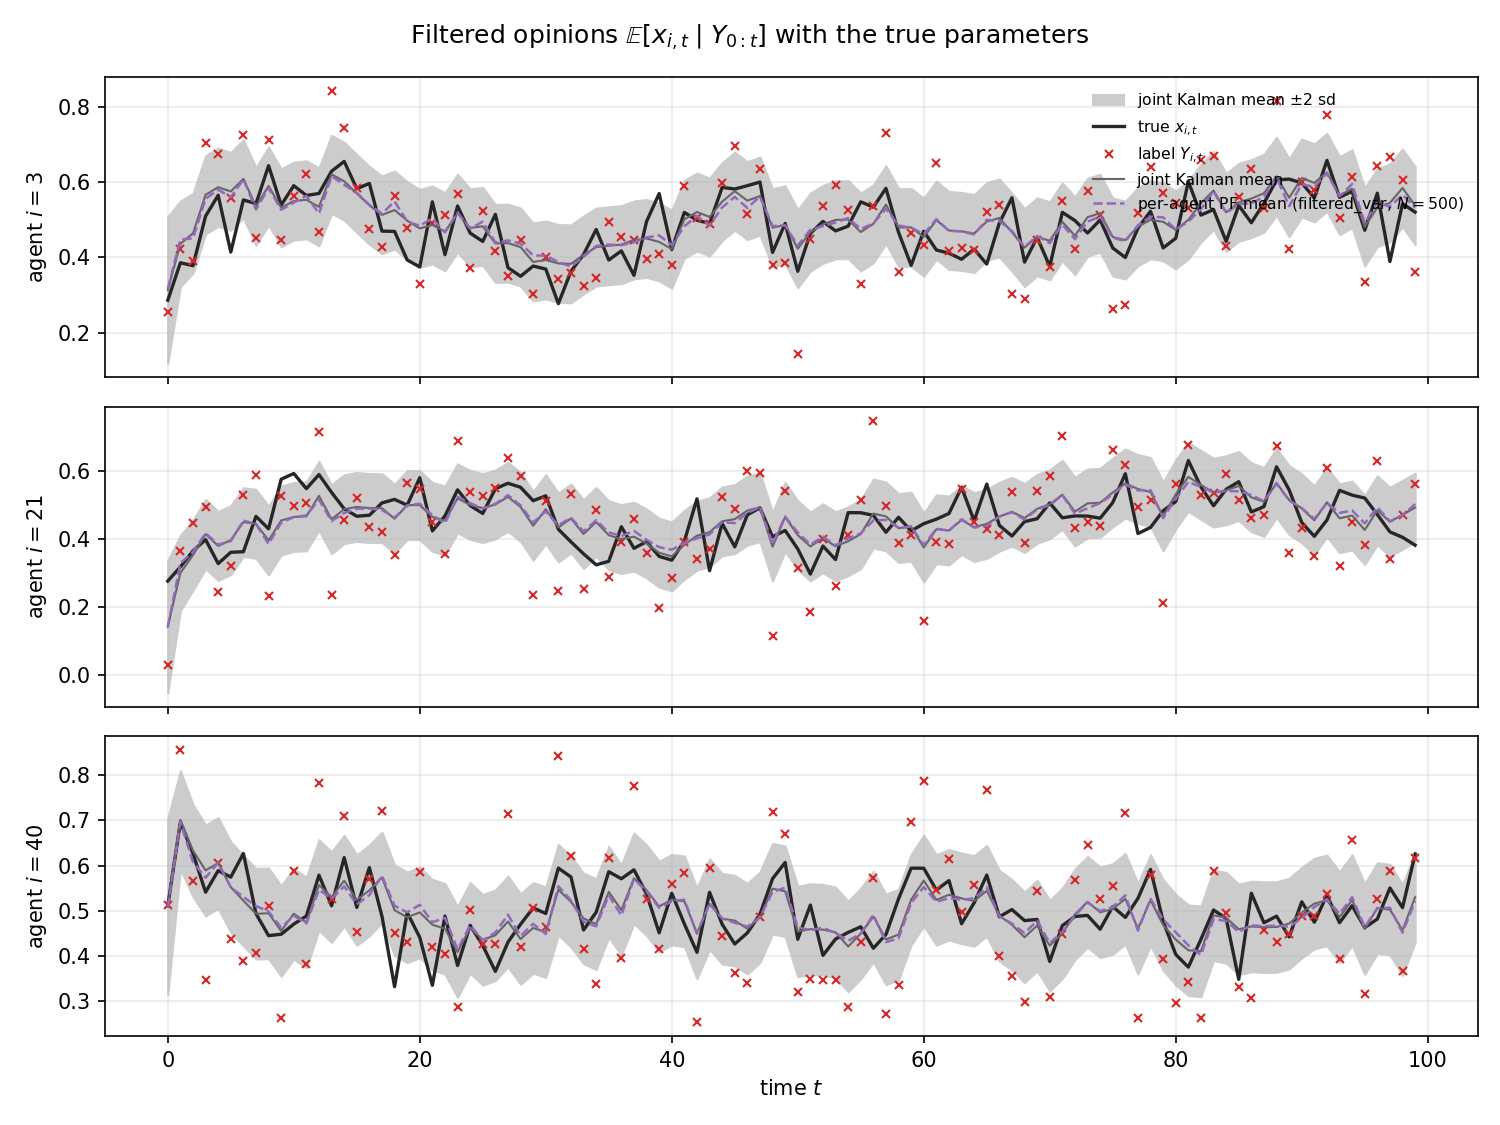

| estimate of $x$ | RMSE vs true $x$ | $\pm 2$ sd coverage |
|---|---|---|
| labels $Y$ (no filtering) | 0.1123 | — |
| joint Kalman (exact) | 0.0522 | 0.953 |
| per-agent Kalman, observed | 0.0565 | — |
| per-agent Kalman, filtered_var | 0.0528 | 0.949 |
| per-agent PF, filtered_var ($N = 500$) | 0.0529 | — |

In [4]:
section_start = time.perf_counter()
_, joint_means, joint_covariances = kalman.kalman_loglik(labels, W, true_params, simulation_settings, return_filtered=True)
joint_mean = joint_means[:, :n_agents]                                     # x-block of z = [x; s]
joint_var = np.diagonal(joint_covariances[:, :n_agents, :n_agents], axis1=1, axis2=2)
_, observed_filter = kalman.per_agent_kalman_loglik(labels, W, true_params, simulation_settings,
                                                    return_filtered=True, input_mode="observed")
_, corrected_filter = kalman.per_agent_kalman_loglik(labels, W, true_params, simulation_settings,
                                                     return_filtered=True, input_mode="filtered_var")
_, particle_output = per_agent_pf_loglik(labels, W, true_params, simulation_settings, 500, np.random.default_rng(0),
                                         return_filtered=True, input_mode="filtered_var")

fig, axes = plt.subplots(len(SHOWN_AGENTS), 1, figsize=(10, 7.5), sharex=True)
for ax, agent in zip(axes, SHOWN_AGENTS):
    band = 2 * np.sqrt(joint_var[:, agent])
    ax.fill_between(time_steps, joint_mean[:, agent] - band, joint_mean[:, agent] + band, color="0.8",
                    label=r"joint Kalman mean $\pm 2$ sd")
    ax.plot(time_steps, opinions[:, agent], color="0.15", linewidth=1.6, label=r"true $x_{i,t}$")
    ax.plot(time_steps, labels[:, agent], color="C3", linestyle="none", marker="x", markersize=4, label=r"label $Y_{i,t}$")
    ax.plot(time_steps, joint_mean[:, agent], color="0.4", linewidth=1.0, label="joint Kalman mean")
    ax.plot(time_steps, particle_output["filtered_mean"][:, agent], color="C4", linewidth=1.2, linestyle="--",
            label=r"per-agent PF mean (filtered_var, $N = 500$)")
    style_axes(ax, r"time $t$" if agent == SHOWN_AGENTS[-1] else "", rf"agent $i = {agent}$",
               legend=agent == SHOWN_AGENTS[0], legend_location="upper right", legend_fontsize=7.5)
fig.suptitle(r"Filtered opinions $\mathbb{E}[x_{i,t} \mid Y_{0:t}]$ with the true parameters")
show_figure(fig, "filtered_opinions.png")


def rmse(estimate):
    return np.sqrt(np.mean((estimate - opinions) ** 2))


def coverage(mean, var):
    return np.mean(np.abs(opinions - mean) <= 2 * np.sqrt(var))


show_table(["estimate of $x$", "RMSE vs true $x$", r"$\pm 2$ sd coverage"], [
    ["labels $Y$ (no filtering)", f"{rmse(labels):.4f}", "—"],
    ["joint Kalman (exact)", f"{rmse(joint_mean):.4f}", f"{coverage(joint_mean, joint_var):.3f}"],
    ["per-agent Kalman, observed", f"{rmse(observed_filter['filtered_mean']):.4f}", "—"],
    ["per-agent Kalman, filtered_var", f"{rmse(corrected_filter['filtered_mean']):.4f}",
     f"{coverage(corrected_filter['filtered_mean'], corrected_filter['filtered_var']):.3f}"],
    ["per-agent PF, filtered_var ($N = 500$)", f"{rmse(particle_output['filtered_mean']):.4f}", "—"],
])
section_runtimes["2. Recovering hidden opinions"] = time.perf_counter() - section_start

**Takeaway.** Filtering halves the error: RMSE falls from $0.112$ (raw labels) to $0.052$ for the exact joint Kalman, and the per-agent filter with `filtered_var` inputs is almost as good ($0.053$ in both its Kalman and PF versions, against $0.057$ with raw `observed` inputs). The $\pm 2$ sd bands are calibrated, covering the true $x$ $95.3\%$ (joint) and $94.9\%$ (per-agent) of the time.

## 3. The likelihood landscape

**Question:** where does the likelihood put $\lambda$, how sharply, and how does $\lambda$ trade off against the noise parameters?

First the profile $\ell(\lambda) = \log p(Y \mid \lambda, \sigma_p, \sigma_e)$ with $\sigma_p, \sigma_e$ at their true values, for the exact joint Kalman and the per-agent Kalman with each neighbour-input mode; each curve is shifted so its maximum is 0. Look at where each curve peaks relative to the true $\lambda$ and how wide it is at the $-2$ level (roughly a 95% interval for one parameter). Then the joint surface over $(\lambda, \sigma_e)$.

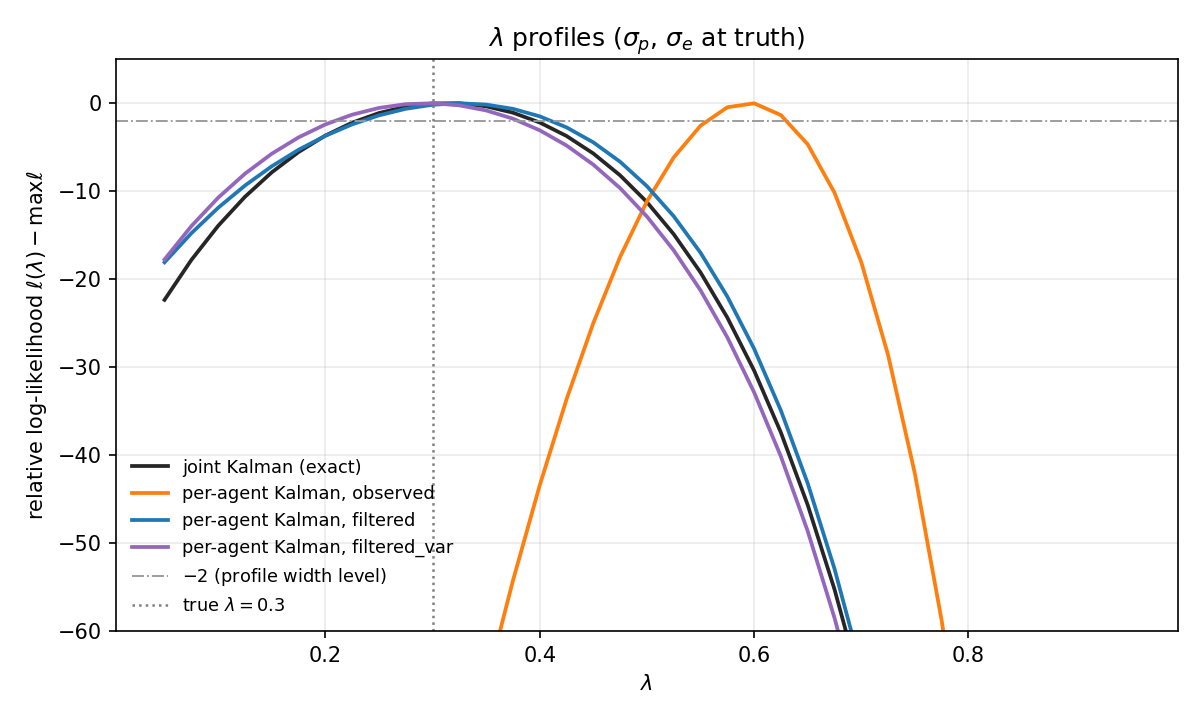

| method | argmax $\lambda$ | 2-unit width |
|---|---|---|
| joint Kalman (exact) | 0.325 | 0.166 |
| per-agent Kalman, observed | 0.600 | 0.073 |
| per-agent Kalman, filtered | 0.325 | 0.176 |
| per-agent Kalman, filtered_var | 0.300 | 0.171 |

In [5]:
section_start = time.perf_counter()
PROFILE_GRID = np.linspace(0.05, 0.95, 37)
METHODS = ("joint", *INPUT_MODES)
METHOD_LABELS = {"joint": "joint Kalman (exact)", "observed": "per-agent Kalman, observed",
                 "filtered": "per-agent Kalman, filtered", "filtered_var": "per-agent Kalman, filtered_var"}
METHOD_COLORS = {"joint": "0.15", "observed": "C1", "filtered": "C0", "filtered_var": "C4"}


def profiles_by_method(data_labels, model_params, grid):
    """λ profile (other parameters fixed at model_params) for the joint Kalman and each per-agent input mode."""
    profiles = {"joint": self_weight_profile(
        lambda params: kalman.kalman_loglik(data_labels, W, params, simulation_settings), model_params, grid)}
    for input_mode in INPUT_MODES:
        profiles[input_mode] = self_weight_profile(
            lambda params: kalman.per_agent_kalman_loglik(data_labels, W, params, simulation_settings,
                                                          input_mode=input_mode), model_params, grid)
    return profiles


profiles = profiles_by_method(labels, true_params, PROFILE_GRID)
plot_self_weight_profiles(
    FIGURE_DIR / "lambda_profiles.png", PROFILE_GRID,
    [ProfileCurve(profiles[method], METHOD_LABELS[method], {"color": METHOD_COLORS[method], "linewidth": 1.8})
     for method in METHODS],
    true_params.self_weight, r"$\lambda$ profiles ($\sigma_p$, $\sigma_e$ at truth)",
    width_level=2.0, figsize=(8, 4.8), legend_fontsize=8.5,
)
display(Image(filename=str(FIGURE_DIR / "lambda_profiles.png")))
show_table(["method", r"argmax $\lambda$", "2-unit width"], [
    [METHOD_LABELS[method], f"{PROFILE_GRID[profiles[method].argmax()]:.3f}", f"{profile_width(PROFILE_GRID, profiles[method]):.3f}"]
    for method in METHODS
])

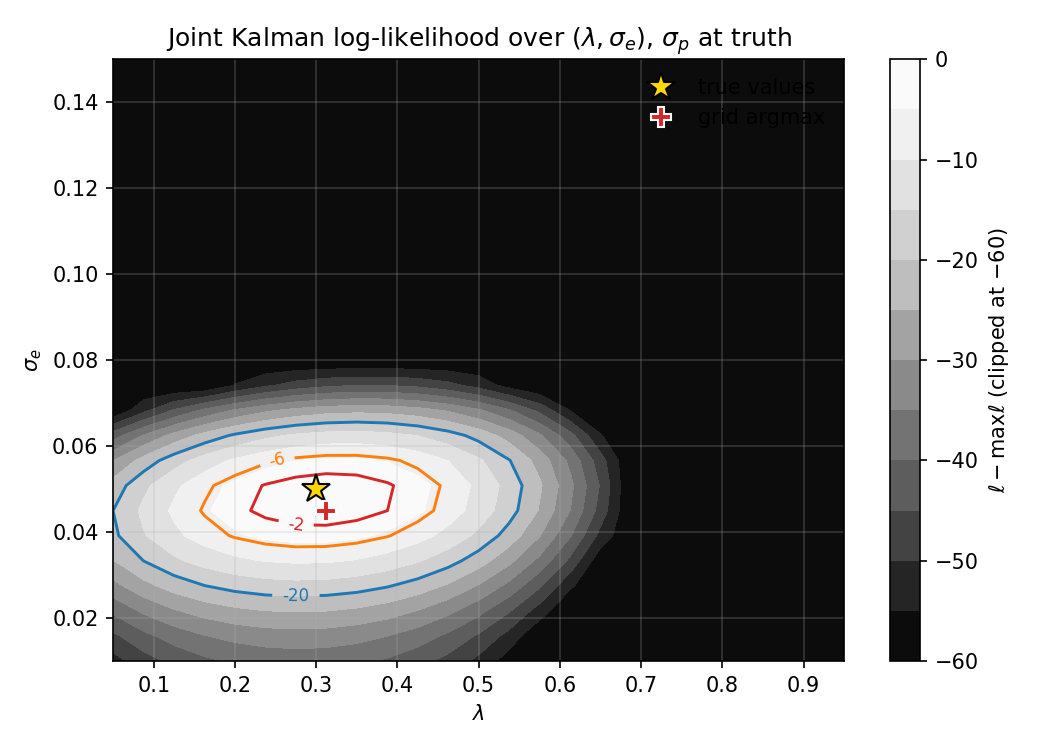

grid argmax: λ = 0.312, σ_e = 0.0450; ℓ(truth) − max ℓ = 0.17


In [6]:
SURFACE_SELF_WEIGHTS = np.linspace(0.05, 0.95, 25)
SURFACE_EXPRESSION_NOISES = np.linspace(0.01, 0.15, 25)


def joint_loglik_at(point):
    self_weight, expression_noise_sd = point
    params = replace(true_params, self_weight=float(self_weight), expression_noise_sd=float(expression_noise_sd))
    return kalman.kalman_loglik(labels, W, params, simulation_settings)


grid_points = [(self_weight, noise_sd) for noise_sd in SURFACE_EXPRESSION_NOISES for self_weight in SURFACE_SELF_WEIGHTS]
with ProcessPoolExecutor() as pool:
    surface = np.array(list(pool.map(joint_loglik_at, grid_points, chunksize=25))).reshape(
        SURFACE_EXPRESSION_NOISES.size, SURFACE_SELF_WEIGHTS.size)
relative_surface = surface - surface.max()
best_row, best_column = np.unravel_index(surface.argmax(), surface.shape)

fig, ax = plt.subplots(figsize=(7, 5))
filled = ax.contourf(SURFACE_SELF_WEIGHTS, SURFACE_EXPRESSION_NOISES, np.maximum(relative_surface, -60),
                     levels=np.linspace(-60, 0, 13), cmap="Greys_r")
fig.colorbar(filled, ax=ax, label=r"$\ell - \max \ell$ (clipped at $-60$)")
contours = ax.contour(SURFACE_SELF_WEIGHTS, SURFACE_EXPRESSION_NOISES, relative_surface, levels=[-20, -6, -2],
                      colors=["C0", "C1", "C3"], linewidths=1.4)
ax.clabel(contours, fmt="%g", fontsize=8)
ax.plot(true_params.self_weight, true_params.expression_noise_sd, marker="*", markersize=14, color="gold",
        markeredgecolor="black", linestyle="none", label="true values")
ax.plot(SURFACE_SELF_WEIGHTS[best_column], SURFACE_EXPRESSION_NOISES[best_row], marker="P", markersize=10, color="C3",
        markeredgecolor="white", linestyle="none", label="grid argmax")
style_axes(ax, r"$\lambda$", r"$\sigma_e$", r"Joint Kalman log-likelihood over $(\lambda, \sigma_e)$, $\sigma_p$ at truth")
show_figure(fig, "loglik_surface_lambda_sigma_e.png")
print(f"grid argmax: λ = {SURFACE_SELF_WEIGHTS[best_column]:.3f}, σ_e = {SURFACE_EXPRESSION_NOISES[best_row]:.4f}; "
      f"ℓ(truth) − max ℓ = {joint_loglik_at((true_params.self_weight, true_params.expression_noise_sd)) - surface.max():.2f}")
section_runtimes["3. Likelihood landscape"] = time.perf_counter() - section_start

**Takeaway.** With $\sigma_p, \sigma_e$ at truth, the exact and both corrected profiles peak at $\lambda = 0.30$–$0.325$ with 2-unit widths $0.17$–$0.18$, while raw `observed` inputs peak at $0.60$ with a width of only $0.07$, confidently wrong (the same numbers as `check_plugin_bias.py`). The $(\lambda, \sigma_e)$ surface with $\sigma_p$ fixed is a nearly axis-aligned ellipse: the $-2$ contour spans $\lambda \approx 0.22$–$0.40$ but only $\sigma_e \approx 0.043$–$0.053$, so with $\sigma_p$ known, $\sigma_e$ is sharply identified and barely trades off against $\lambda$; the positive $\lambda$–$\sigma_e$ correlation seen in section 5 comes through $\sigma_p$ once it is free. The truth is $0.17$ units below the grid maximum ($\lambda = 0.31$, $\sigma_e = 0.045$).

## 4. The plug-in bias and its correction

**Question:** when neighbours' expressions are replaced by their labels, how wrong does the per-agent estimate of $\lambda$ get as the measurement noise grows, and do the corrected inputs fix it?

A lighter version of `checks/check_plugin_bias.py`: for $\sigma_m \in \{0.02, 0.05, 0.1, 0.2\}$, 10 datasets each on the same network (data seeds 100–109), $\hat\lambda$ = argmax of the profile on a 46-point grid, other parameters at their true values. Look at how far each method's mean $\hat\lambda$ drifts from the true value.

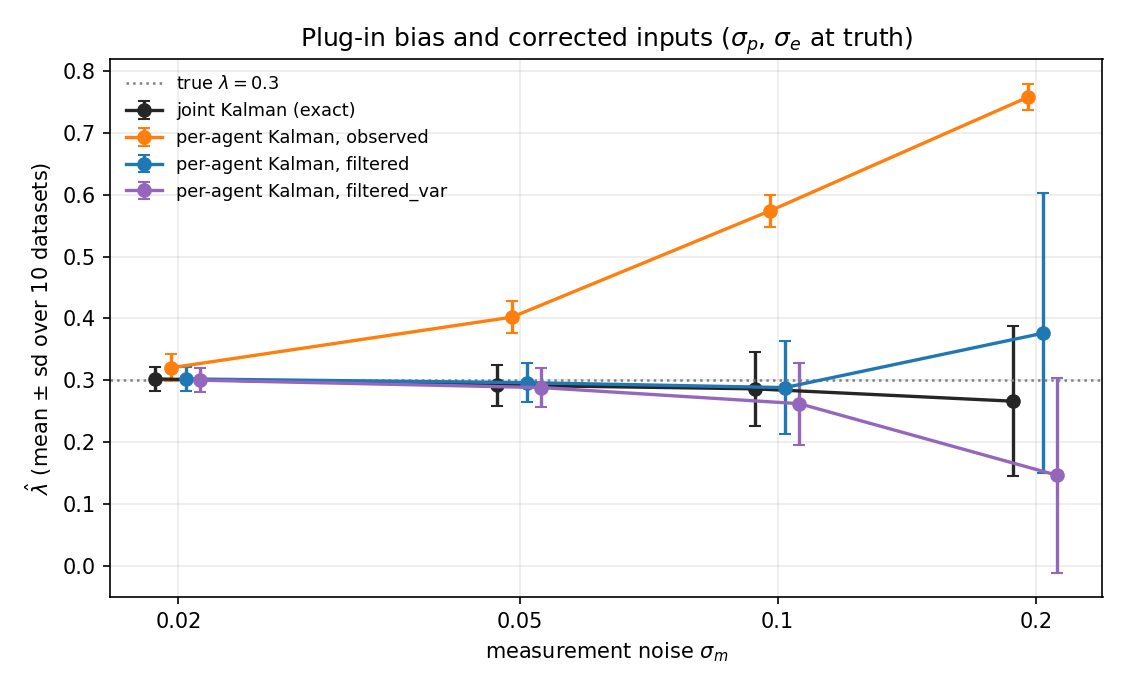

| $\sigma_m$ | joint Kalman (exact) | per-agent Kalman, observed | per-agent Kalman, filtered | per-agent Kalman, filtered_var |
|---|---|---|---|---|
| 0.02 | 0.302 ± 0.019 | 0.320 ± 0.022 | 0.302 ± 0.019 | 0.300 ± 0.019 |
| 0.05 | 0.292 ± 0.033 | 0.402 ± 0.025 | 0.296 ± 0.031 | 0.288 ± 0.032 |
| 0.1 | 0.286 ± 0.059 | 0.574 ± 0.026 | 0.288 ± 0.075 | 0.262 ± 0.066 |
| 0.2 | 0.266 ± 0.121 | 0.758 ± 0.021 | 0.376 ± 0.226 | 0.146 ± 0.158 |

In [7]:
section_start = time.perf_counter()
MEASUREMENT_NOISE_LEVELS = [0.02, 0.05, 0.1, 0.2]
DATASET_SEEDS = range(100, 110)
ESTIMATION_GRID = np.linspace(0.05, 0.95, 46)


def estimate_self_weight(task):
    """λ̂ by each method for one dataset simulated with measurement noise σ_m on the baseline network."""
    measurement_noise_sd, dataset_seed = task
    noise_config = with_model_params(config, measurement_noise_sd=measurement_noise_sd)
    noisy_labels = simulate.simulate(noise_config, W=W, rng=np.random.default_rng(dataset_seed))["y"]
    method_profiles = profiles_by_method(noisy_labels, noise_config.model, ESTIMATION_GRID)
    return measurement_noise_sd, {method: ESTIMATION_GRID[profile.argmax()] for method, profile in method_profiles.items()}


tasks = [(noise_sd, seed) for noise_sd in MEASUREMENT_NOISE_LEVELS for seed in DATASET_SEEDS]
with ProcessPoolExecutor() as pool:
    estimates = list(pool.map(estimate_self_weight, tasks))
estimates_by_level = {
    noise_sd: {method: np.array([by_method[method] for level, by_method in estimates if level == noise_sd])
               for method in METHODS}
    for noise_sd in MEASUREMENT_NOISE_LEVELS
}

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for method, offset in zip(METHODS, (0.94, 0.98, 1.02, 1.06)):
    ax.errorbar(np.array(MEASUREMENT_NOISE_LEVELS) * offset,
                [estimates_by_level[level][method].mean() for level in MEASUREMENT_NOISE_LEVELS],
                yerr=[estimates_by_level[level][method].std(ddof=1) for level in MEASUREMENT_NOISE_LEVELS],
                color=METHOD_COLORS[method], capsize=3, label=METHOD_LABELS[method], **POINTS_STYLE)
mark_true_value(ax, true_params.self_weight, axis="y")
set_log_ticks(ax, MEASUREMENT_NOISE_LEVELS)
style_axes(ax, r"measurement noise $\sigma_m$", r"$\hat\lambda$ (mean $\pm$ sd over 10 datasets)",
           r"Plug-in bias and corrected inputs ($\sigma_p$, $\sigma_e$ at truth)", legend_fontsize=8.5)
show_figure(fig, "bias_vs_measurement_noise.png")

show_table([r"$\sigma_m$", *[METHOD_LABELS[method] for method in METHODS]], [
    [noise_sd, *[f"{estimates_by_level[noise_sd][method].mean():.3f} ± {estimates_by_level[noise_sd][method].std(ddof=1):.3f}"
                 for method in METHODS]]
    for noise_sd in MEASUREMENT_NOISE_LEVELS
])
section_runtimes["4. Plug-in bias"] = time.perf_counter() - section_start

**Takeaway.** Raw labels as inputs bias $\hat\lambda$ upward more and more as $\sigma_m$ grows ($0.32, 0.40, 0.57, 0.76$ against a true $0.3$), with a small spread that hides the error. Both corrected modes track the exact joint estimate up to the baseline $\sigma_m = 0.1$ ($0.288$ and $0.262$ vs $0.286$), but break down at $\sigma_m = 0.2$: `filtered` becomes unstable ($0.376 \pm 0.226$) and `filtered_var` biased low ($0.146 \pm 0.158$), while the joint estimate is $0.266 \pm 0.121$. This is the pattern of `check_plugin_bias.py` (20 datasets, finer grid); there `filtered` averaged $0.311$ at $\sigma_m = 0.2$, and the higher $0.376$ here reflects only 10 datasets with an sd of $0.23$.

## 5. Posterior inference (λ, σ_p and σ_e estimated jointly)

**Question:** what is the joint posterior $p(\lambda, \sigma_p, \sigma_e \mid Y)$, does the particle-filter sampler reproduce the exact one for the same model, and what does the per-agent approximation cost?

Random-walk Metropolis–Hastings on $\theta = (\mathrm{logit}\,\lambda, \log\sigma_p, \log\sigma_e)$ with the priors of `configs/inference_base.yaml`, adaptive proposal during burn-in, all chains started at the true $\psi$ (this tests sampling, not search):

- **A** exact MH on the joint Kalman likelihood (the exact model);
- **B** exact MH on the per-agent Kalman likelihood, `filtered_var` inputs;
- **D** correlated PMMH on the noise-driven per-agent particle filter, `filtered_var`, $N$ and $\rho$ from the config: the filter's random numbers $u$ move with $u' = \rho u + \sqrt{1-\rho^2}\,\varepsilon$ and are accepted together with $\psi'$.

These are shortened runs (4000 iterations, 1000 burn-in); `checks/check_pmmh.py` runs the full length (10000, 2000). Look at whether D agrees with B (same likelihood, so it should up to Monte Carlo error) and how both differ from A.

In [8]:
section_start = time.perf_counter()
mcmc_settings = replace(inference_config.mcmc, n_iterations=4000, burn_in=1000)
CHAIN_LABELS = {"A": "exact MH, joint Kalman", "B": "exact MH, per-agent Kalman, filtered_var",
                "D": "correlated PMMH, per-agent PF, filtered_var"}
CHAIN_COLORS = {"A": "0.15", "B": "C0", "D": "C3"}
PARAMETER_SYMBOLS = {"self_weight": r"\lambda", "process_noise_sd": r"\sigma_p", "expression_noise_sd": r"\sigma_e"}
pmmh_settings = inference_config.pmmh


def run_chain(task):
    """Run one chain from the true ψ; returns (name, sampler output)."""
    chain_name, seed_sequence = task
    pseudo_marginal = {}
    if chain_name == "A":
        loglik_fn = lambda params, noise: kalman.kalman_loglik(labels, W, params, simulation_settings)
    elif chain_name == "B":
        loglik_fn = lambda params, noise: kalman.per_agent_kalman_loglik(labels, W, params, simulation_settings,
                                                                         input_mode="filtered_var")
    else:
        loglik_fn = lambda params, noise: per_agent_pf_loglik_given_noise(labels, W, params, simulation_settings, noise,
                                                                          input_mode=pmmh_settings.input_mode)
        pseudo_marginal = {"draw_noise": lambda rng: draw_per_agent_noise(n_steps, pmmh_settings.n_particles, n_agents, rng),
                           "rho": pmmh_settings.rho}
    result = inference.pseudo_marginal_mh(loglik_fn, inference.to_unconstrained(true_params), true_params,
                                          inference_config.priors, mcmc_settings, np.random.default_rng(seed_sequence),
                                          **pseudo_marginal)
    return chain_name, result


chain_seeds = np.random.SeedSequence(inference_config.seed).spawn(len(CHAIN_LABELS))
with ProcessPoolExecutor(max_workers=len(CHAIN_LABELS)) as pool:
    chains = dict(pool.map(run_chain, zip(CHAIN_LABELS, chain_seeds)))
kept_draws = {name: chain["params"][mcmc_settings.burn_in:] for name, chain in chains.items()}

rows = []
for chain_name, chain in chains.items():
    for column, parameter in enumerate(inference.PARAMETER_NAMES):
        draws = kept_draws[chain_name][:, column]
        low, high = np.quantile(draws, [0.025, 0.975])
        rows.append([chain_name, rf"${PARAMETER_SYMBOLS[parameter]}$", f"{draws.mean():.4f}", f"[{low:.4f}, {high:.4f}]",
                     "yes" if low <= true_values[parameter] <= high else "**no**",
                     f"{inference.effective_sample_size(draws):.0f}",
                     f"{chain['accepted'][mcmc_settings.burn_in:].mean():.2f}", f"{chain['runtime_s']:.0f} s"])
show_table(["chain", "parameter", "mean", "95% interval", "covers truth", "ESS", "acceptance", "runtime"], rows)
print("true values: " + ", ".join(f"{name} = {value}" for name, value in true_values.items()))


def monte_carlo_se(draws):
    return draws.std(ddof=1) / np.sqrt(inference.effective_sample_size(draws))


print("D − B in Monte Carlo standard errors (sampler check): " + ", ".join(
    f"{parameter} {(kept_draws['D'][:, column].mean() - kept_draws['B'][:, column].mean()) / np.hypot(monte_carlo_se(kept_draws['D'][:, column]), monte_carlo_se(kept_draws['B'][:, column])):+.1f}"
    for column, parameter in enumerate(inference.PARAMETER_NAMES)))

| chain | parameter | mean | 95% interval | covers truth | ESS | acceptance | runtime |
|---|---|---|---|---|---|---|---|
| A | $\lambda$ | 0.3300 | [0.2353, 0.4314] | yes | 199 | 0.23 | 169 s |
| A | $\sigma_p$ | 0.0447 | [0.0308, 0.0599] | yes | 190 | 0.23 | 169 s |
| A | $\sigma_e$ | 0.0524 | [0.0353, 0.0650] | yes | 160 | 0.23 | 169 s |
| B | $\lambda$ | 0.2602 | [0.1901, 0.3436] | yes | 161 | 0.21 | 6 s |
| B | $\sigma_p$ | 0.0610 | [0.0487, 0.0702] | yes | 59 | 0.21 | 6 s |
| B | $\sigma_e$ | 0.0336 | [0.0096, 0.0546] | yes | 42 | 0.21 | 6 s |
| D | $\lambda$ | 0.2742 | [0.1898, 0.3628] | yes | 113 | 0.21 | 266 s |
| D | $\sigma_p$ | 0.0581 | [0.0451, 0.0684] | yes | 48 | 0.21 | 266 s |
| D | $\sigma_e$ | 0.0394 | [0.0177, 0.0569] | yes | 62 | 0.21 | 266 s |

true values: self_weight = 0.3, process_noise_sd = 0.05, expression_noise_sd = 0.05
D − B in Monte Carlo standard errors (sampler check): self_weight +2.6, process_noise_sd -2.4, expression_noise_sd +2.5


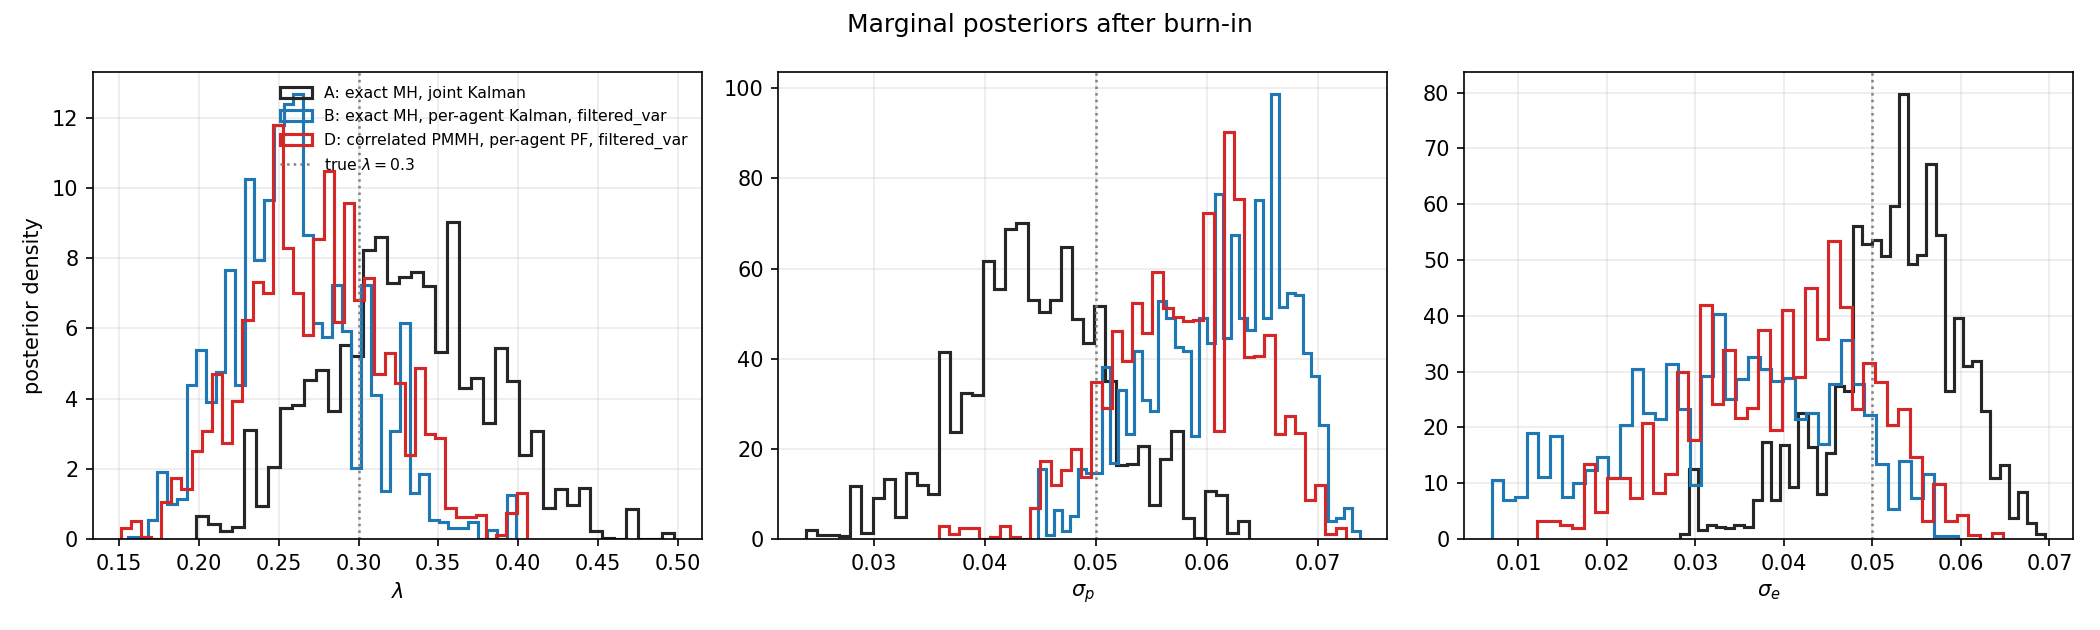

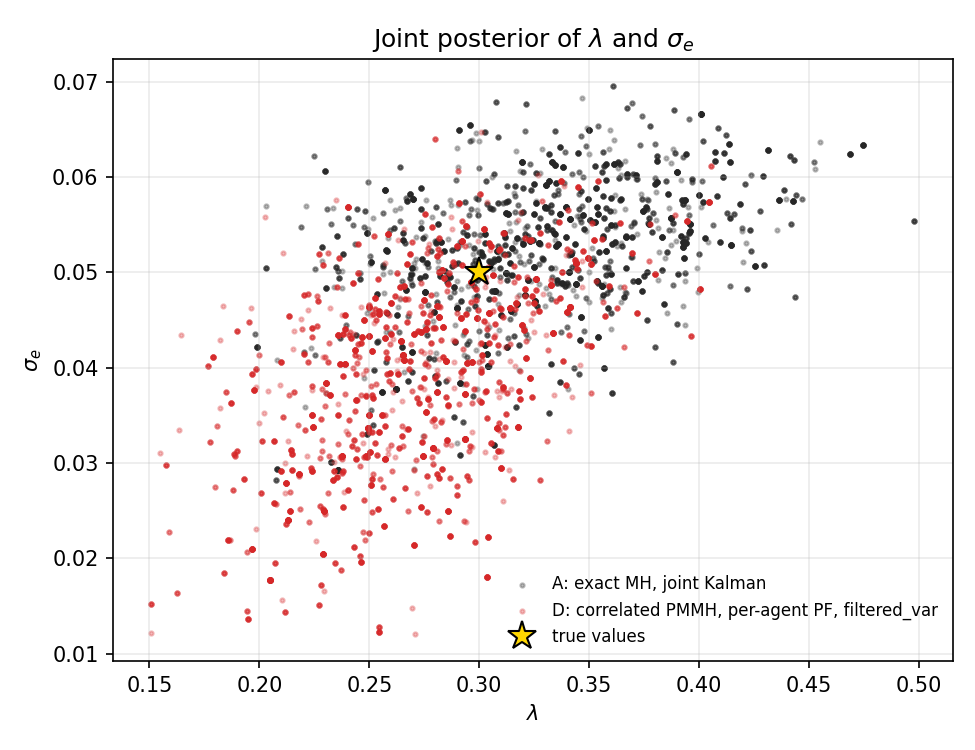

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (column, parameter) in zip(axes, enumerate(inference.PARAMETER_NAMES)):
    for chain_name in CHAIN_LABELS:
        ax.hist(kept_draws[chain_name][:, column], bins=40, density=True, histtype="step", linewidth=1.5,
                color=CHAIN_COLORS[chain_name], label=f"{chain_name}: {CHAIN_LABELS[chain_name]}")
    mark_true_value(ax, true_values[parameter], symbol=PARAMETER_SYMBOLS[parameter])
    style_axes(ax, rf"${PARAMETER_SYMBOLS[parameter]}$", "posterior density" if column == 0 else "",
               legend=column == 0, legend_fontsize=7.5)
fig.suptitle("Marginal posteriors after burn-in")
show_figure(fig, "posterior_marginals.png")

fig, ax = plt.subplots(figsize=(6.5, 5))
for chain_name in ("A", "D"):
    ax.scatter(kept_draws[chain_name][:, 0], kept_draws[chain_name][:, 2], s=4, alpha=0.3,
               color=CHAIN_COLORS[chain_name], label=f"{chain_name}: {CHAIN_LABELS[chain_name]}")
ax.plot(true_params.self_weight, true_params.expression_noise_sd, marker="*", markersize=14, color="gold",
        markeredgecolor="black", linestyle="none", label="true values")
style_axes(ax, r"$\lambda$", r"$\sigma_e$", r"Joint posterior of $\lambda$ and $\sigma_e$", legend_fontsize=8)
show_figure(fig, "posterior_lambda_sigma_e.png")

### Opinions with parameter uncertainty

For 100 posterior draws $\psi^{(k)}$ from chain D (evenly spaced after burn-in), rerun the per-agent Kalman filter (`filtered_var`) at $\psi^{(k)}$ and collect its filtered means $\mathbb{E}[x_{i,t} \mid Y_{0:t}, \psi^{(k)}]$. The 5–95% band across draws shows how the uncertainty about $\psi$ carries over to the reconstructed opinions, i.e. the parameter part of $p(x_{i,t} \mid Y_{0:t})$ with $\psi$ integrated out; the full posterior band would also add each draw's own filtered variance (section 2). The per-agent Kalman filter is used here only because it is fast and exact for the per-agent model that chain D samples.

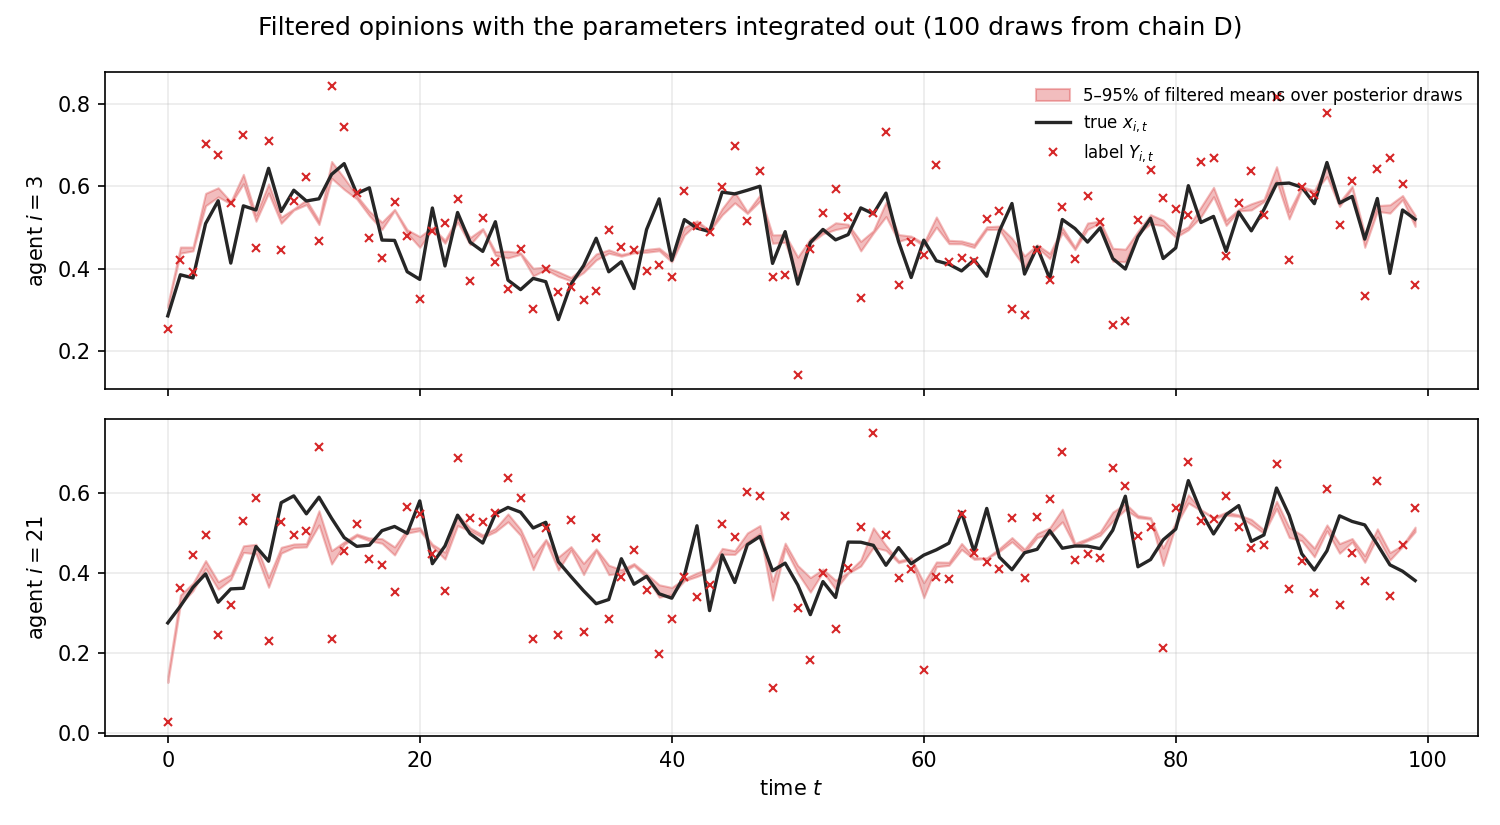

band width (5–95%) over all agents and times: median 0.0120, max 0.0694; joint Kalman filtered sd with true ψ (section 2): median 0.0508


In [10]:
draw_indices = np.linspace(mcmc_settings.burn_in, mcmc_settings.n_iterations - 1, 100).astype(int)
filtered_means_by_draw = np.array([
    kalman.per_agent_kalman_loglik(labels, W, inference.from_unconstrained(chains["D"]["theta"][index], true_params),
                                   simulation_settings, return_filtered=True, input_mode="filtered_var")[1]["filtered_mean"]
    for index in draw_indices
])
band_low, band_high = np.quantile(filtered_means_by_draw, [0.05, 0.95], axis=0)

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for ax, agent in zip(axes, SHOWN_AGENTS[:2]):
    ax.fill_between(time_steps, band_low[:, agent], band_high[:, agent], color="C3", alpha=0.3,
                    label=r"5–95% of filtered means over posterior draws")
    ax.plot(time_steps, opinions[:, agent], color="0.15", linewidth=1.6, label=r"true $x_{i,t}$")
    ax.plot(time_steps, labels[:, agent], color="C3", linestyle="none", marker="x", markersize=4, label=r"label $Y_{i,t}$")
    style_axes(ax, r"time $t$" if agent == SHOWN_AGENTS[1] else "", rf"agent $i = {agent}$",
               legend=agent == SHOWN_AGENTS[0], legend_location="upper right", legend_fontsize=8)
fig.suptitle(r"Filtered opinions with the parameters integrated out (100 draws from chain D)")
show_figure(fig, "opinions_with_parameter_uncertainty.png")
band_width = band_high - band_low
print(f"band width (5–95%) over all agents and times: median {np.median(band_width):.4f}, max {band_width.max():.4f}; "
      f"joint Kalman filtered sd with true ψ (section 2): median {np.median(np.sqrt(joint_var)):.4f}")
section_runtimes["5. Posterior inference"] = time.perf_counter() - section_start

**Takeaway.** All 95% intervals cover the truth, but the per-agent posteriors (B, D) are shifted away from the exact one (A): $\lambda$ $0.26$–$0.27$ vs $0.33$, $\sigma_p$ $0.058$–$0.061$ vs $0.045$, $\sigma_e$ $0.034$–$0.039$ vs $0.052$, i.e. the per-agent model trades expression noise for process noise, as in `check_pmmh.py`. In this shortened run D does **not** quite reproduce B: its means differ by $+2.6$, $-2.4$ and $+2.5$ Monte Carlo standard errors, all in the direction of A, with ESS of only $42$–$113$; the full-length run in `check_pmmh.py` (10 000 iterations) found D and B within $0.7$ s.e., so the gap is most likely due to the short chains, but this run alone cannot show that. Parameter uncertainty adds little to the reconstructed opinions: the 5–95% band of filtered means across posterior draws has median width $0.012$, against a filtered sd of about $0.051$ with known parameters.

## Runtime

In [11]:
show_table(["section", "runtime"], [[name, f"{seconds:.0f} s"] for name, seconds in section_runtimes.items()]
           + [["total", f"{sum(section_runtimes.values()):.0f} s"]])

| section | runtime |
|---|---|
| 0. Setup | 0 s |
| 1. Data-generating process | 0 s |
| 2. Recovering hidden opinions | 0 s |
| 3. Likelihood landscape | 8 s |
| 4. Plug-in bias | 19 s |
| 5. Posterior inference | 266 s |
| total | 294 s |